# Topological signatures of human activity

This notebook presents the already tested analysis in `ANALYSIS_SPEC.md`. It
does not implement a second experiment pipeline. Run `run_analysis.py` first;
the notebook reads its numerical arrays and results, then explains and plots
them in the mathematical order used by the course.

**Question.** Does the topology of short acceleration and gyroscope
trajectories distinguish activities for subjects not used for training?

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from ripser import ripser

from data import ACTIVITIES, load_split
from tda import GRID, delay_cloud, mean_autocorrelation, normalize_cloud

ROOT = Path.cwd()
if not (ROOT / "ANALYSIS_SPEC.md").exists():
    raise RuntimeError("Start Jupyter from the project directory")
if not (ROOT / "output/results.json").exists():
    raise RuntimeError("Run `.venv/bin/python run_analysis.py` before this notebook")

results = json.loads((ROOT / "output/results.json").read_text())
cache = ROOT / "output/cache"
delay = np.load(cache / "delay_m3_lag15_f47.npz")
instantaneous = np.load(cache / "instantaneous_m1_lag1_f47.npz")
shuffled = np.load(cache / "shuffled_m3_lag15_seed2956_f47.npz")
train, labels, subjects = load_split("train")
test, test_labels, test_subjects = load_split("test")

print("Development windows:", len(labels))
print("Official test windows:", len(test_labels))
print("Subjects are disjoint:", set(subjects).isdisjoint(test_subjects))

Development windows: 7352
Official test windows: 2947
Subjects are disjoint: True


## 1. One observation is a sampled path

For sensor (s\in\{a,g\}), one observation is

\[
x^{(s)}:\{0,\ldots,127\}\to\mathbb R^3.
\]

The 128 samples are recorded at 50 Hz, so each labelled window lasts 2.56
seconds. The official split separates people, not merely windows.

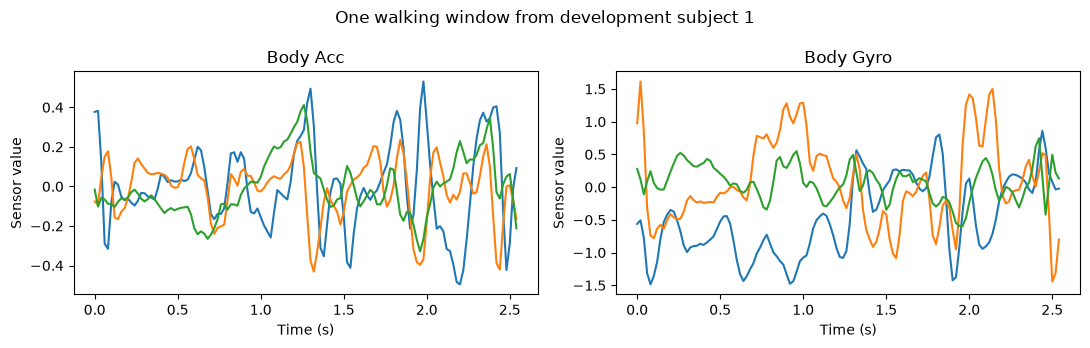

In [2]:
index = np.flatnonzero((subjects == 1) & (labels == 1))[0]
time = np.arange(128) / 50
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharex=True)
for axis, sensor in zip(axes, ("body_acc", "body_gyro")):
    axis.plot(time, train[sensor][index])
    axis.set_title(sensor.replace("_", " ").title())
    axis.set_xlabel("Time (s)")
    axis.set_ylabel("Sensor value")
fig.suptitle("One walking window from development subject 1")
fig.tight_layout()

## 2. Delay coordinates create the finite metric space

For embedding dimension (m) and lag (\ell),

\[
E_{m,\ell}(x)_t=(x_t,x_{t+\ell},\ldots,x_{t+(m-1)\ell})
\in\mathbb R^{3m}.
\]

We use (m=3) and (\ell=15), producing 98 points in
(\mathbb R^9). The lag is the first non-positive mean acceleration
autocorrelation; it is not selected by classification performance.

Chosen lag: 15


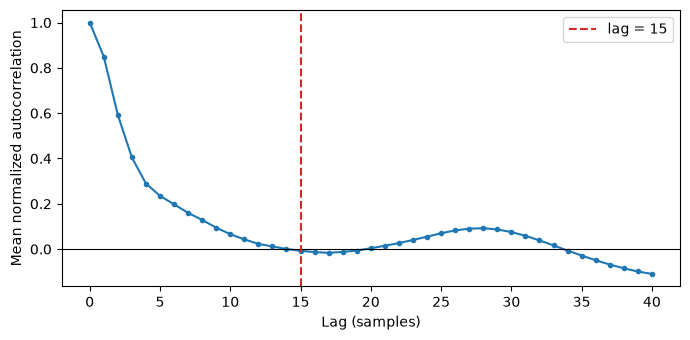

In [3]:
autocorrelation = mean_autocorrelation(train["body_acc"], max_lag=40)
chosen_lag = int(np.flatnonzero(autocorrelation[1:] <= 0)[0] + 1)
plt.figure(figsize=(7, 3.5))
plt.plot(np.arange(41), autocorrelation, marker="o", markersize=3)
plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(chosen_lag, color="tab:red", linestyle="--", label=f"lag = {chosen_lag}")
plt.xlabel("Lag (samples)")
plt.ylabel("Mean normalized autocorrelation")
plt.legend()
plt.tight_layout()
print("Chosen lag:", chosen_lag)

For a delay cloud (X=\{z_i\}_{i=1}^n), define

\[
r(X)=\left(\frac1n\sum_i\lVert z_i-\bar z\rVert_2^2\right)^{1/2},
\qquad
\widetilde X=\left\{\frac{z_i-\bar z}{r(X)}\right\}.
\]

This removes translation and global amplitude from the primary topology. The
two discarded sensor radii are retained for one explicit scale comparison.

Cloud shape: (98, 9) raw RMS radius: 0.5179


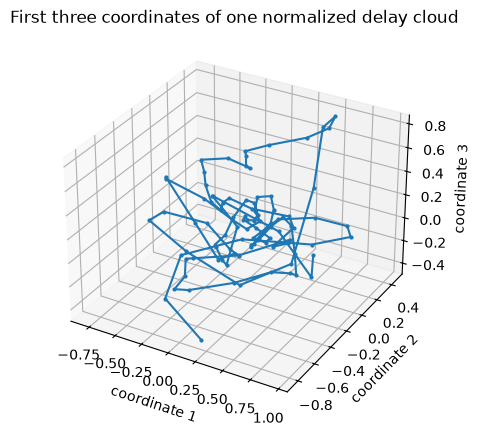

In [4]:
raw_cloud = delay_cloud(train["body_acc"][index], m=3, lag=15)
cloud, radius = normalize_cloud(raw_cloud)
fig = plt.figure(figsize=(6, 5))
axis = fig.add_subplot(projection="3d")
axis.plot(cloud[:, 0], cloud[:, 1], cloud[:, 2], marker="o", markersize=2)
axis.set_title("First three coordinates of one normalized delay cloud")
axis.set_xlabel("coordinate 1")
axis.set_ylabel("coordinate 2")
axis.set_zlabel("coordinate 3")
print("Cloud shape:", cloud.shape, "raw RMS radius:", round(radius, 4))

## 3. Vietoris-Rips persistence and stable ranks

For the normalized finite metric space ((X,d)),

\[
\operatorname{VR}_\epsilon(X)=
\{\sigma\subseteq X:d(x,y)\leq\epsilon\text{ for every }x,y\in\sigma\}.
\]

We compute (H_0) and (H_1) persistence over (\mathbb F_{47}). The field
is shared with the circular cocycle extension, allowing one persistence pass
to produce both representations.

For finite diagram (D_k), the lifetime stable rank is

\[
\rho_k(u)=\#\{(b,d)\in D_k:d-b>u\}.
\]

It is evaluated at 64 fixed thresholds on ([0,2]). Each window has four
blocks: acceleration (H_0,H_1), then gyroscope (H_0,H_1).

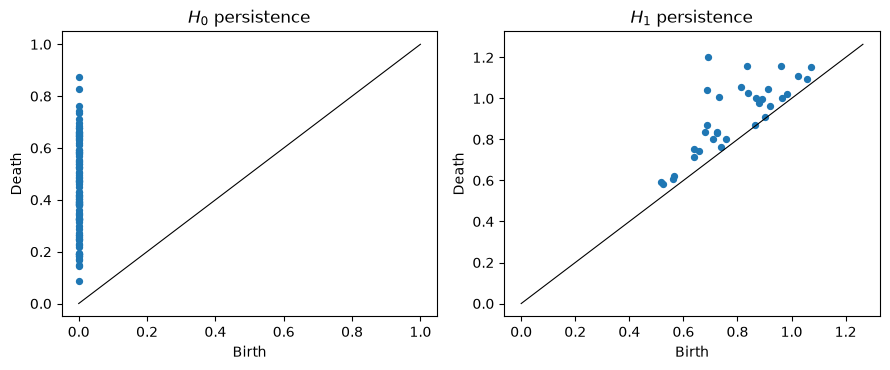

In [5]:
diagram = ripser(cloud, maxdim=1, coeff=47)["dgms"]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for dimension, axis in enumerate(axes):
    finite = diagram[dimension][np.isfinite(diagram[dimension][:, 1])]
    limit = max(1.0, finite.max() * 1.05) if len(finite) else 1.0
    axis.scatter(finite[:, 0], finite[:, 1], s=18)
    axis.plot((0, limit), (0, limit), color="black", linewidth=0.8)
    axis.set(title=f"$H_{dimension}$ persistence", xlabel="Birth", ylabel="Death")
fig.tight_layout()

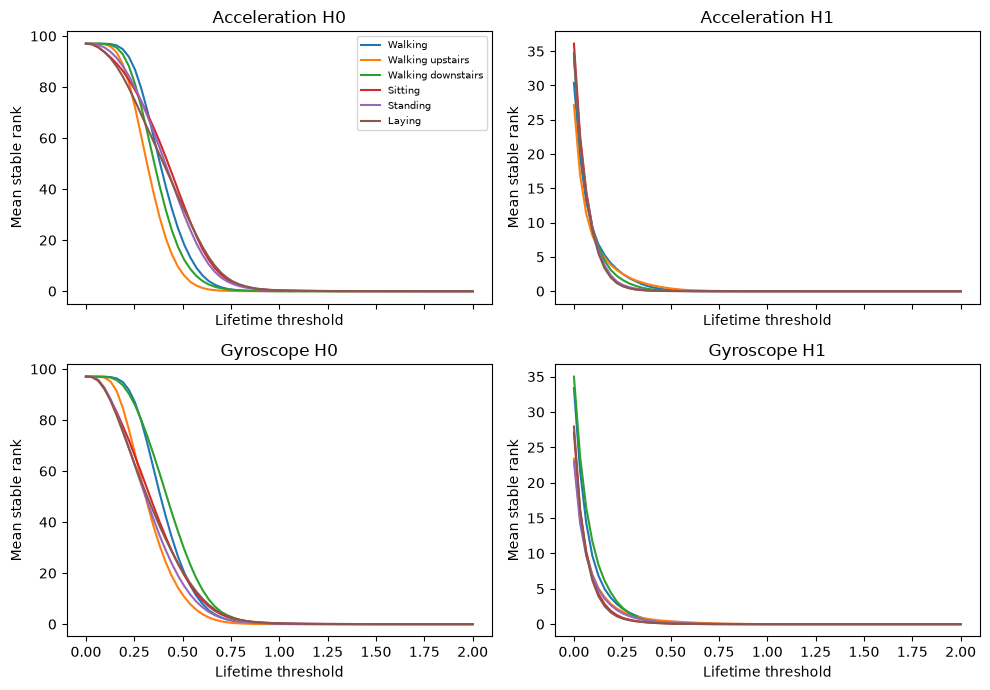

In [6]:
ranks = delay["train_ranks"]
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True)
titles = ("Acceleration H0", "Acceleration H1", "Gyroscope H0", "Gyroscope H1")
for block, (axis, title) in enumerate(zip(axes.flat, titles)):
    start = block * len(GRID)
    for activity, name in ACTIVITIES.items():
        axis.plot(GRID, ranks[labels == activity, start:start + len(GRID)].mean(axis=0),
                  label=name)
    axis.set_title(title)
    axis.set_ylabel("Mean stable rank")
    axis.set_xlabel("Lifetime threshold")
axes[0, 0].legend(fontsize=7)
fig.tight_layout()

## 4. The five comparisons

The classifier is deliberately fixed for every representation:

\[
\operatorname{StandardScaler}\to
\operatorname{RBF\ SVM}(C=10,\gamma=0.001).
\]

Development estimates use five stratified subject-grouped folds. The official
test contains nine entirely different subjects. There is no hyperparameter
search and no representation-specific tuning.

The shuffled control independently permutes the 128 samples of every window
before delay embedding. It preserves the multiset of sensor values while
destroying temporal adjacency.

Instantaneous TDA         BA=0.558  F1=0.553
Delay TDA                 BA=0.580  F1=0.576
Shuffled-delay TDA        BA=0.499  F1=0.483
Delay TDA + scale         BA=0.639  F1=0.640
Topological dynamics      BA=0.568  F1=0.564
UCI 561 baseline          BA=0.954  F1=0.955


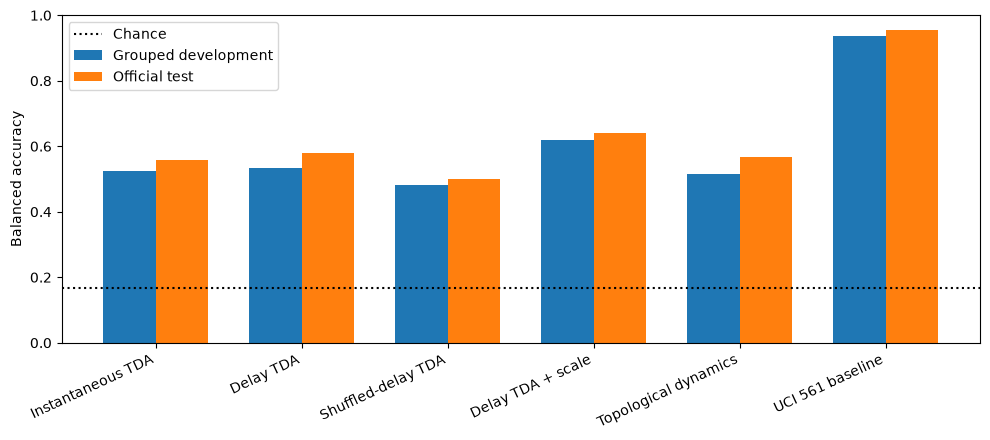

In [7]:
names = list(results["models"])
development = [results["models"][name]["development"]["balanced_accuracy"] for name in names]
official = [results["models"][name]["official_test"]["balanced_accuracy"] for name in names]
x = np.arange(len(names))
plt.figure(figsize=(10, 4.5))
plt.bar(x - 0.18, development, 0.36, label="Grouped development")
plt.bar(x + 0.18, official, 0.36, label="Official test")
plt.axhline(1 / 6, color="black", linestyle=":", label="Chance")
plt.xticks(x, names, rotation=25, ha="right")
plt.ylabel("Balanced accuracy")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
for name in names:
    score = results["models"][name]["official_test"]
    print(f"{name:25s} BA={score['balanced_accuracy']:.3f}  F1={score['macro_f1']:.3f}")

The important comparisons are qualitative and were specified before this
rewrite:

- delay TDA exceeds shuffled-delay TDA, so temporal adjacency contributes;
- restoring the two physical scales improves normalized topology;
- compact dynamics remains competitive with the 256 sampled stable ranks;
- engineered UCI features remain much stronger, so topology is interpreted
  rather than sold as the best classifier.

## 5. Cross-subject activity geometry

For subject (p) and activity (c), let

\[
\mu_{p,c}=\frac1{N_{p,c}}\sum_{i:p_i=p,y_i=c}\Phi_{\mathrm{SR}}(x_i).
\]

The matrix below averages blockwise stable-rank (L^1) distances between
subject-activity prototypes. It describes structure without fitting another
classifier.

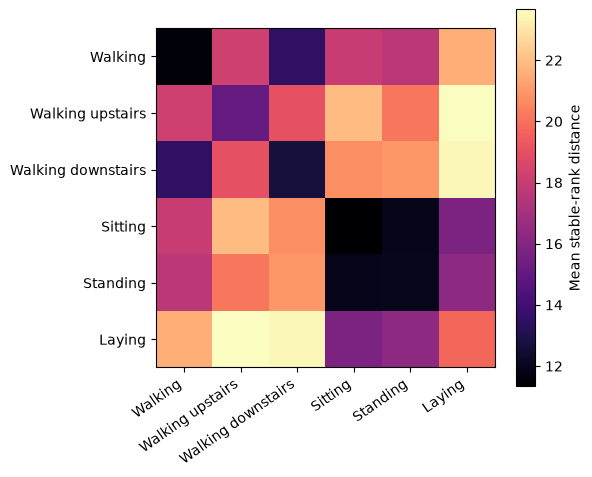

In [8]:
matrix = np.asarray(results["activity_distance_matrix"])
plt.figure(figsize=(6, 5))
plt.imshow(matrix, cmap="magma")
plt.colorbar(label="Mean stable-rank distance")
activity_names = list(ACTIVITIES.values())
plt.xticks(range(6), activity_names, rotation=35, ha="right")
plt.yticks(range(6), activity_names)
plt.tight_layout()

## 6. Persistent loops as circular motion coordinates

For the longest (H_1) bar ((b^*,d^*)), use its Ripser cocycle on the Rips
graph at

\[
\epsilon^*=b^*+\tfrac12(d^*-b^*).
\]

After lifting the cocycle (\alpha), anchor one vertex and solve

\[
\widehat\phi=\arg\min_{\phi:\phi_0=0}\lVert B\phi+\alpha\rVert_2^2,
\qquad \theta_i=\widehat\phi_i\bmod1.
\]

The slope of unwrapped (2\pi\theta_i) gives circular frequency; regression
(R^2) gives phase linearity. Together with six direct diagram summaries per
sensor this produces a compact 16-dimensional representation.

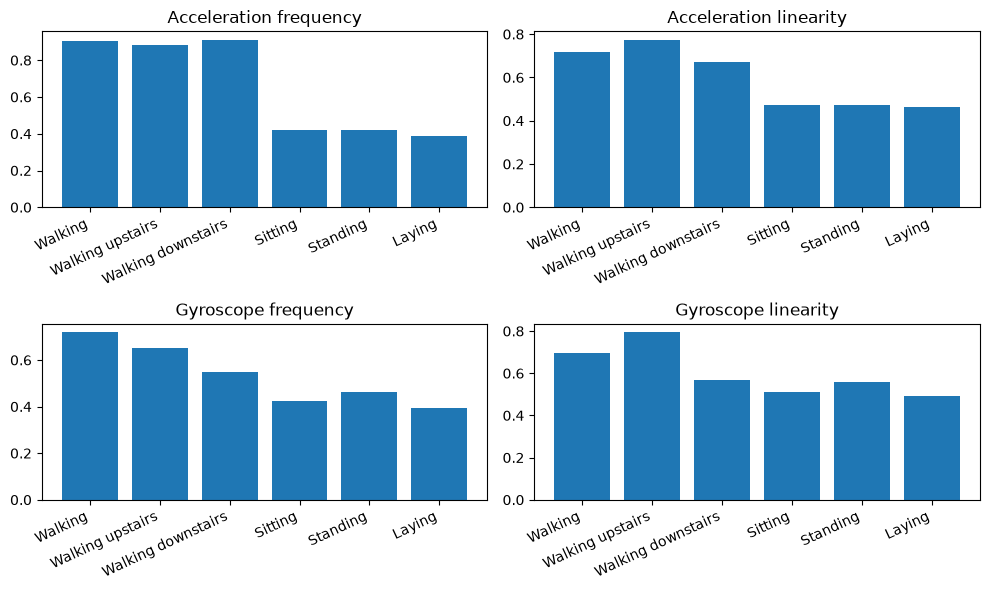

In [9]:
dynamics = delay["train_dynamics"]
columns = (6, 7, 14, 15)
titles = ("Acceleration frequency", "Acceleration linearity",
          "Gyroscope frequency", "Gyroscope linearity")
means = np.asarray([
    [dynamics[labels == activity, column].mean() for activity in ACTIVITIES]
    for column in columns
])
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for axis, values, title in zip(axes.flat, means, titles):
    axis.bar(range(6), values)
    axis.set_title(title)
    axis.set_xticks(range(6), list(ACTIVITIES.values()), rotation=25, ha="right")
fig.tight_layout()

## 7. Bounded perturbation check

On a deterministic balanced sample, independent Gaussian noise equal to 5%
of each window/channel standard deviation is added before recomputing delay
topology. This illustrates gradual displacement under perturbation; it is not
presented as a proof of the course stability theorem.

In [10]:
noise = results["noise_5_percent"]
print("Windows:", noise["sample_size"])
print("Mean stable-rank displacement:", round(noise["mean_distance"], 3))
print("95% empirical interval:",
      (round(noise["q025"], 3), round(noise["q975"], 3)))

Windows: 60
Mean stable-rank displacement: 2.607
95% empirical interval: (1.856, 4.187)


## 8. Conclusion

The clean analysis supports a narrow result. Delay-cloud topology transfers
activity information across subjects and performs better than topology after
temporal shuffling. Normalization removes highly predictive physical scale,
which becomes visible when the two radii are restored. The compact
persistence-and-dynamics vector is interpretable and competitive, but the
engineered UCI representation remains substantially stronger.

These conclusions come from five prespecified representations, one fixed
model, one subject-grouped development protocol, and one official disjoint
test—without the previous experiment framework.